<a href="https://colab.research.google.com/github/u7po00/bishkek-smog-alert/blob/main/bishkek_air_alert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bishkek Smog Alert: does knowing about the "air trap" make next-day warnings better?

**Veritas AI Hackathon 2026 · Climate track · next-day air quality forecast**

Bishkek sits in a valley and burns coal for heating. On winter nights a layer of warm air can sit on top of cold air (a temperature inversion) and trap the smoke over the city.

This notebook:

1. forecasts tomorrow's average PM2.5 in Bishkek from measured data and compares it with a naive guess ("tomorrow = today");
2. turns the forecast into a **bad-air alert** and tunes it so that missing a bad day counts 5x worse than a false alarm;
3. **tests one hypothesis**: does giving the model a measure of the inversion make the forecast and the alert better?
4. shows what drives the smog, which bad days the alert missed, an honest range for each forecast, and how accuracy drops 2 and 3 days ahead;
5. prints the alert in Kyrgyz, Russian and English.

**How to run:** Runtime -> Run all. It downloads its own data and takes a few minutes. No GPU needed.

This is a prototype, not health advice.

In [1]:
import io
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

LAT, LON = 42.8746, 74.5698          # central Bishkek, about 800 m above sea level
LAT_M, LON_M = 42.55, 74.50          # Kyrgyz Ala-Too mountains, about 35 km south of the city
TZ = "Asia/Bishkek"
START = "2019-01-01"
END = (pd.Timestamp.now(tz=TZ) - pd.Timedelta(days=7)).strftime("%Y-%m-%d")

BAD = 55.5                           # daily PM2.5 (ug/m3) where the US AQI turns "Unhealthy"
BAD_LABEL = "Unhealthy (US AQI)"
MISS_COST, FALSE_ALARM_COST = 5, 1   # a missed bad day counts 5x a false alarm
WINTER = [11, 12, 1, 2]

## 1. Data

**PM2.5.** Hourly measurements from the monitor at the US Embassy in Bishkek, in AirNow format. The notebook takes them from the copy archived on Zenodo with a Bishkek air-quality study (2019 to mid-2024), or from AirNow's own yearly files. If neither can be downloaded it falls back to PM2.5 from the CAMS global atmosphere model through Open-Meteo, which is a model estimate and not a measurement. The notebook prints which one it used.

**Weather.** Open-Meteo's Historical Weather API (ERA5 reanalysis) for two places: the city, and a point in the mountains about 35 km south and roughly two kilometres higher. The mountain temperature is what lets us measure the inversion.

In [2]:
def get_json(url, params):
    r = requests.get(url, params=params, timeout=180)
    if r.status_code != 200:
        raise RuntimeError(f"{url} -> {r.status_code}: {r.text[:300]}")
    return r.json()


def parse_airnow(df):
    # AirNow hourly files: Year, Month, Day, Hour, "Raw Conc.", "QC Name"; -999 marks invalid readings
    df.columns = [c.strip() for c in df.columns]
    if "QC Name" in df.columns:
        df = df[df["QC Name"].astype(str).str.strip() == "Valid"]
    time = pd.to_datetime(dict(year=df["Year"], month=df["Month"], day=df["Day"], hour=df["Hour"]),
                          errors="coerce")
    out = pd.DataFrame({"time": time.values,
                        "pm25": pd.to_numeric(df["Raw Conc."], errors="coerce").values}).dropna()
    out = out[(out["pm25"] >= 0) & (out["pm25"] < 1500)]
    return out.drop_duplicates("time").set_index("time").sort_index()


def load_embassy_zenodo():
    # Embassy measurements for 2019 to mid-2024, archived with a Bishkek air-quality study on Zenodo.
    import glob
    import os
    import subprocess
    try:
        url = ("https://zenodo.org/records/12720883/files/"
               "bishkek_monitoring_us.embassy2019-2024.rar?download=1")
        r = requests.get(url, timeout=180)
        r.raise_for_status()
        with open("embassy.rar", "wb") as f:
            f.write(r.content)
        os.makedirs("embassy", exist_ok=True)
        try:
            ok = subprocess.run(["unrar", "x", "-o+", "embassy.rar", "embassy/"],
                                capture_output=True).returncode == 0
        except FileNotFoundError:
            ok = False
        if not ok:
            subprocess.run(["7z", "x", "-y", "-oembassy", "embassy.rar"], capture_output=True)
        files = sorted(glob.glob("embassy/**/*.csv", recursive=True))
        print("  files:", [os.path.basename(f) for f in files])
        if not files:
            return None
        return parse_airnow(pd.concat([pd.read_csv(f) for f in files], ignore_index=True))
    except Exception as e:
        print("  Zenodo archive failed:", type(e).__name__, str(e)[:200])
        return None


def load_embassy():
    # The same monitor, straight from AirNow (one file per year).
    frames = []
    for year in range(2019, 2027):
        url = f"https://dosairnowdata.org/dos/historical/Bishkek/{year}/Bishkek_PM2.5_{year}_YTD.csv"
        try:
            r = requests.get(url, timeout=60)
            if r.status_code == 200 and "Raw Conc" in r.text[:2000]:
                frames.append(pd.read_csv(io.StringIO(r.text)))
        except Exception:
            pass
    return parse_airnow(pd.concat(frames, ignore_index=True)) if frames else None


def load_cams():
    # Hourly PM2.5 from the CAMS global model (Open-Meteo Air Quality API).
    j = None
    for start in ("2022-08-01", "2022-10-01", "2023-01-01"):
        try:
            j = get_json("https://air-quality-api.open-meteo.com/v1/air-quality", dict(
                latitude=LAT, longitude=LON, hourly="pm2_5",
                start_date=start, end_date=END, timezone=TZ))
            break
        except RuntimeError as e:
            print("  ", e)
    if j is None:
        raise RuntimeError("No PM2.5 source could be downloaded.")
    out = pd.DataFrame({"time": pd.to_datetime(j["hourly"]["time"]),
                        "pm25": j["hourly"]["pm2_5"]}).dropna()
    return out.set_index("time").sort_index()


print("Trying the US Embassy monitor (Zenodo archive)...")
pm_hourly = load_embassy_zenodo()
PM_SOURCE = "US Embassy Bishkek monitor (measured), archived on Zenodo (record 12720883)"
if pm_hourly is None or len(pm_hourly[START:]) < 24 * 500:
    print("Trying the US Embassy monitor (AirNow yearly files)...")
    pm_hourly = load_embassy()
    PM_SOURCE = "US Embassy Bishkek monitor (measured), via AirNow"
if pm_hourly is not None:
    pm_hourly = pm_hourly[START:]
if pm_hourly is None or len(pm_hourly) < 24 * 500:
    print("Embassy data not usable, falling back to the CAMS model...")
    pm_hourly = load_cams()
    PM_SOURCE = "CAMS global model via Open-Meteo (modelled, NOT measured)"
print("PM2.5 source:", PM_SOURCE)
print(pm_hourly.index.min(), "to", pm_hourly.index.max(), "|", len(pm_hourly), "hourly values")

Trying the US Embassy monitor (Zenodo archive)...
  files: ['Bishkek_PM2.5_2019_YTD.csv', 'Bishkek_PM2.5_2020_YTD.csv', 'Bishkek_PM2.5_2021_YTD.csv', 'Bishkek_PM2.5_2022_YTD.csv', 'Bishkek_PM2.5_2023_YTD.csv', 'Bishkek_PM2.5_2024_YTD.csv']
PM2.5 source: US Embassy Bishkek monitor (measured), archived on Zenodo (record 12720883)
2019-02-06 06:00:00 to 2024-06-30 23:00:00 | 44514 hourly values


In [3]:
ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"
W_START = pm_hourly.index.min().strftime("%Y-%m-%d")
W_END = min(END, (pm_hourly.index.max() + pd.Timedelta(days=4)).strftime("%Y-%m-%d"))


def load_archive(lat, lon, variables):
    frames, elevation = [], None
    for year in range(int(W_START[:4]), int(W_END[:4]) + 1):
        s, e = max(W_START, f"{year}-01-01"), min(W_END, f"{year}-12-31")
        j = get_json(ARCHIVE, dict(latitude=lat, longitude=lon, hourly=",".join(variables),
                                   start_date=s, end_date=e, timezone=TZ))
        elevation = j.get("elevation", elevation)
        frames.append(pd.DataFrame(j["hourly"]))
    wx = pd.concat(frames, ignore_index=True)
    wx["time"] = pd.to_datetime(wx["time"])
    return wx.set_index("time").sort_index(), elevation


wx_hourly, ELEV_CITY = load_archive(LAT, LON, ["temperature_2m", "wind_speed_10m", "relative_humidity_2m",
                                               "precipitation", "surface_pressure"])
mountain, ELEV_MOUNTAIN = load_archive(LAT_M, LON_M, ["temperature_2m"])
wx_hourly["temperature_mountain"] = mountain["temperature_2m"]
try:
    blh, _ = load_archive(LAT, LON, ["boundary_layer_height"])
    wx_hourly["boundary_layer_height"] = blh["boundary_layer_height"]
except Exception as err:
    print("Boundary layer height not available from this archive:", str(err)[-120:])
try:
    extra, _ = load_archive(LAT, LON, ["cloud_cover", "snow_depth", "wind_direction_10m"])
    for c in extra.columns:
        wx_hourly[c] = extra[c]
except Exception as err:
    print("Cloud, snow and wind direction not available:", str(err)[-120:])

print(f"City point: {ELEV_CITY:.0f} m | mountain point: {ELEV_MOUNTAIN:.0f} m "
      f"({ELEV_MOUNTAIN - ELEV_CITY:.0f} m higher)")
print(wx_hourly.notna().mean().round(2).to_string())   # share of hours with data, per variable

City point: 749 m | mountain point: 2631 m (1882 m higher)
temperature_2m           1.00
wind_speed_10m           1.00
relative_humidity_2m     1.00
precipitation            1.00
surface_pressure         1.00
temperature_mountain     1.00
boundary_layer_height    0.91
cloud_cover              1.00
snow_depth               1.00
wind_direction_10m       1.00


## 2. One row per day

The inversion measure is **mountain temperature minus city temperature**. Normally the mountains are much colder than the city, so this number is strongly negative. When it climbs towards zero, the air is barely cooling with height: a warm lid is sitting over the valley and the smoke cannot escape.

Bad-air limit: 55.5 ug/m3 = Unhealthy (US AQI); 12% of days are bad
Air-trap features: ['inversion_mean', 'inversion_night', 'inversion_hours', 'blh_mean', 'blh_min']
1841 days with PM2.5, from 2019-02-06 to 2024-06-30


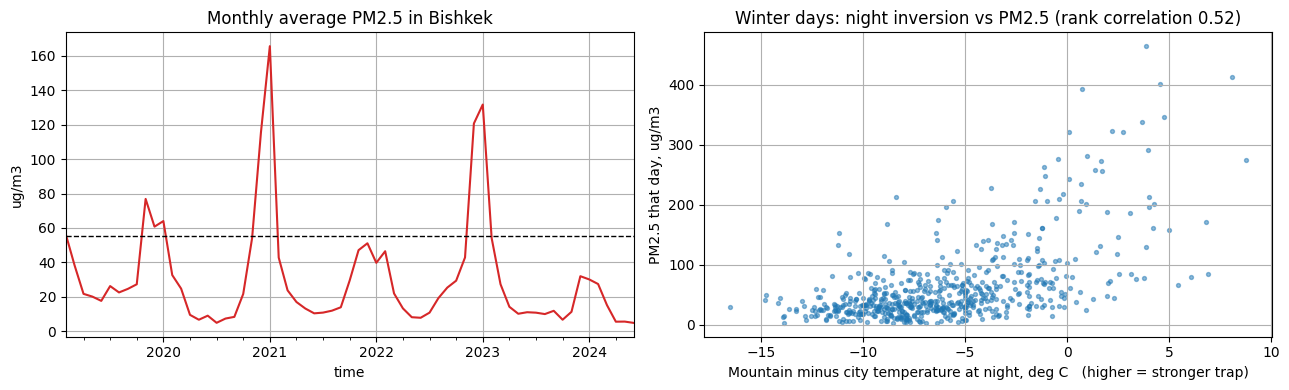

,days with data,bad days,winter mean PM2.5
2018/19,145,6,56.4
2019/20,345,56,58.8
2020/21,332,58,95.3
2021/22,333,38,45.9
2022/23,347,58,88.5
2023/24,339,14,25.1


In [4]:
# Daily PM2.5: keep only days with at least 18 hourly values
g = pm_hourly["pm25"].resample("D")
pm_daily = g.mean()[g.count() >= 18].rename("pm25")

# If almost no day reaches the limit (likely with modelled PM2.5), use a lower one so the alert means something
if (pm_daily >= BAD).mean() < 0.05:
    BAD, BAD_LABEL = 35.5, "Unhealthy for Sensitive Groups (US AQI)"
if (pm_daily >= BAD).mean() < 0.03:
    BAD, BAD_LABEL = float(round(pm_daily.quantile(0.85), 1)), "worst 15% of days in this dataset"
print(f"Bad-air limit: {BAD:g} ug/m3 = {BAD_LABEL}; {(pm_daily >= BAD).mean():.0%} of days are bad")

def daily_weather(hourly):
    # Turns hourly weather into one row per day. Used for the history and for the live forecast.
    wx = hourly.dropna(axis=1, how="all").copy()
    night = wx.index.hour < 8
    agg = {
        "temp": wx["temperature_2m"].resample("D").mean(),
        "temp_min": wx["temperature_2m"].resample("D").min(),
        "wind": wx["wind_speed_10m"].resample("D").mean(),
        "wind_night": wx["wind_speed_10m"][night].resample("D").mean(),
        "humidity": wx["relative_humidity_2m"].resample("D").mean(),
        "precip": wx["precipitation"].resample("D").sum(),
        "pressure": wx["surface_pressure"].resample("D").mean(),
    }
    if "temperature_mountain" in wx.columns:
        inv = wx["temperature_mountain"] - wx["temperature_2m"]          # normally strongly negative
        lapse = -inv / ((ELEV_MOUNTAIN - ELEV_CITY) / 1000)              # deg C lost per km of height
        agg["inversion_mean"] = inv.resample("D").mean()
        agg["inversion_night"] = inv[night].resample("D").mean()
        agg["inversion_hours"] = (lapse < 3).resample("D").sum()         # hours when the air barely cools with height
    if "boundary_layer_height" in wx.columns:
        agg["blh_mean"] = wx["boundary_layer_height"].resample("D").mean()
        agg["blh_min"] = wx["boundary_layer_height"].resample("D").min()
    if "cloud_cover" in wx.columns:
        agg["cloud"] = wx["cloud_cover"].resample("D").mean()
        agg["cloud_night"] = wx["cloud_cover"][night].resample("D").mean()   # clear nights cool the valley floor
    if "snow_depth" in wx.columns:
        agg["snow_depth"] = wx["snow_depth"].resample("D").mean()
    if "wind_direction_10m" in wx.columns:
        rad = np.deg2rad(wx["wind_direction_10m"])
        agg["wind_from_north"] = (wx["wind_speed_10m"] * np.cos(rad)).resample("D").mean()
        agg["wind_from_east"] = (wx["wind_speed_10m"] * np.sin(rad)).resample("D").mean()
    out = pd.DataFrame(agg)
    out["heating"] = (18 - out["temp"]).clip(lower=0)                    # how much heating the day needs
    return out


day = daily_weather(wx_hourly)
HAS_INVERSION = "inversion_night" in day.columns

# Tonight's level and today's peak say more about tomorrow than the daily average does
pm_evening = pm_hourly["pm25"][pm_hourly.index.hour >= 18].resample("D").mean()
pm_peak = pm_hourly["pm25"].resample("D").max()
TRAP_FEATURES = [c for c in day.columns if c.startswith(("inversion", "blh"))]
print("Air-trap features:", TRAP_FEATURES if TRAP_FEATURES else "none available")

both = pd.concat([pm_daily, day], axis=1).dropna(subset=["pm25"])
print(len(both), "days with PM2.5, from", both.index.min().date(), "to", both.index.max().date())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
both["pm25"].resample("MS").mean().plot(ax=ax[0], color="tab:red")
ax[0].axhline(BAD, color="k", ls="--", lw=1)
ax[0].set_title("Monthly average PM2.5 in Bishkek")
ax[0].set_ylabel("ug/m3")
if HAS_INVERSION:
    w = both[both.index.month.isin(WINTER)]
    ax[1].scatter(w["inversion_night"], w["pm25"], s=8, alpha=0.5)
    rho = w[["inversion_night", "pm25"]].corr(method="spearman").iloc[0, 1]
    ax[1].set_title(f"Winter days: night inversion vs PM2.5 (rank correlation {rho:.2f})")
    ax[1].set_xlabel("Mountain minus city temperature at night, deg C   (higher = stronger trap)")
    ax[1].set_ylabel("PM2.5 that day, ug/m3")
plt.tight_layout()
plt.savefig("fig_overview.png", dpi=150, bbox_inches="tight")
plt.show()

# How different are the winters from each other?
season = pd.Series(np.where(both.index.month >= 7, both.index.year, both.index.year - 1), index=both.index)
wint = both[both.index.month.isin(WINTER)]
winters = pd.DataFrame({
    "days with data": both.groupby(season)["pm25"].size(),
    "bad days": (both["pm25"] >= BAD).groupby(season).sum(),
    "winter mean PM2.5": wint.groupby(season[wint.index])["pm25"].mean().round(1),
})
winters.index = [f"{y}/{str(y + 1)[2:]}" for y in winters.index]
winters

## 3. Forecast model

Each row is "today". The model sees PM2.5 from today and the past week (including this evening's level and today's peak), today's weather, and the weather of the target day (temperature, wind and its direction, humidity, rain, pressure, cloud cover, snow depth). It predicts **how much the target day will differ from today**, so with nothing useful to add it falls back to the naive guess.

Testing is walk-forward: a season runs from July to June, and for each season the model is trained only on earlier seasons and then forecasts that one. Every forecast below is for a day the model had never seen.

Honest caveat: the target day's weather comes from a reanalysis (what the weather turned out to be), standing in for a weather forecast. A real day-ahead forecast is less exact. So the model is also trained a second way, seeing only what is known today. A real forecast would land between the two results.

In [5]:
def make_table(h=1):
    # Row for day t -> features known on day t (plus the weather of day t+h), target = PM2.5 on day t+h
    d = pd.concat([pm_daily, day], axis=1).sort_index().asfreq("D")
    X = pd.DataFrame(index=d.index)
    X["pm_today"] = d["pm25"]
    X["pm_yesterday"] = d["pm25"].shift(1)
    X["pm_3day_mean"] = d["pm25"].rolling(3, min_periods=2).mean()
    X["pm_7day_mean"] = d["pm25"].rolling(7, min_periods=4).mean()
    X["pm_evening"] = pm_evening.reindex(d.index)
    X["pm_peak_today"] = pm_peak.reindex(d.index)
    X["pm_change"] = d["pm25"] - d["pm25"].shift(1)
    for c in day.columns:
        X[c + "_today"] = d[c]
        X[c + "_target"] = d[c].shift(-h)
    target_day = X.index + pd.Timedelta(days=h)
    X["season_sin"] = np.sin(2 * np.pi * target_day.dayofyear / 365.25)
    X["season_cos"] = np.cos(2 * np.pi * target_day.dayofyear / 365.25)
    X["weekday"] = target_day.dayofweek
    X["y"] = d["pm25"].shift(-h)
    return X.dropna(subset=["y", "pm_today"])


def fit(X, y, quantile=None):
    # The model learns log(target day) - log(today): the change from today, on a scale that tames the big spikes
    kw = dict(max_iter=200, learning_rate=0.04, max_depth=3, min_samples_leaf=20,
              l2_regularization=1.0, random_state=0)
    if quantile is None:
        m = HistGradientBoostingRegressor(**kw)
    else:
        m = HistGradientBoostingRegressor(loss="quantile", quantile=quantile, **kw)
    return m.fit(X, np.log1p(y) - np.log1p(X["pm_today"]))


def predict(m, X):
    return pd.Series(np.expm1(np.log1p(X["pm_today"]) + m.predict(X)), index=X.index)


def season_of(index, h=1):
    d = index + pd.Timedelta(days=h)
    return pd.Series(np.where(d.month >= 7, d.year, d.year - 1), index=index)


def folds(table, h=1, min_train=450):
    # Walk-forward: test each season with a model trained only on the seasons before it
    s = season_of(table.index, h)
    for ts in sorted(s.unique()):
        tr, te = table[s < ts], table[s == ts]
        if len(tr) >= min_train and len(te) >= 30:
            yield ts, tr, te


def unseen_train_predictions(tr, cols, quantile=None):
    # Forecasts for training days made by models that never saw those days (used to tune the alert and the ranges)
    oof = pd.Series(np.nan, index=tr.index)
    for a, b in TimeSeriesSplit(n_splits=3).split(tr):
        oof.iloc[b] = predict(fit(tr.iloc[a][cols], tr.iloc[a]["y"], quantile), tr.iloc[b][cols]).values
    return oof.dropna()


def alert_stats(actual, alert):
    bad = actual >= BAD
    caught, missed, false = int((bad & alert).sum()), int((bad & ~alert).sum()), int((~bad & alert).sum())
    return {
        "bad days": int(bad.sum()), "caught": caught, "missed": missed, "false alarms": false,
        "recall": round(caught / max(int(bad.sum()), 1), 2),                 # hit rate: share of bad days caught
        "precision": round(caught / max(int(alert.sum()), 1), 2),            # share of alerts that were right
        "CSI": round(caught / max(caught + missed + false, 1), 2),           # critical success index
        "cost": MISS_COST * missed + FALSE_ALARM_COST * false,
    }


GRID = np.round(np.linspace(0.4 * BAD, 1.3 * BAD, 37), 1)


def best_threshold(actual, pred):
    costs = [alert_stats(actual, pred >= g)["cost"] for g in GRID]
    return float(GRID[int(np.argmin(costs))])


def walk_forward(table, cols, h=1, tune_alert=True):
    parts = []
    for ts, tr, te in folds(table, h):
        p = predict(fit(tr[cols], tr["y"]), te[cols])
        th = BAD
        if tune_alert:
            oof = unseen_train_predictions(tr, cols)
            th = best_threshold(tr.loc[oof.index, "y"], oof)
        parts.append(pd.DataFrame({"y": te["y"], "pred": p, "naive": te["pm_today"],
                                   "threshold": th, "season": f"{ts}/{str(ts + 1)[2:]}"}))
    r = pd.concat(parts)
    r["alert"] = r["pred"] >= r["threshold"]
    return r


def is_winter(index, h=1):
    return (index + pd.Timedelta(days=h)).month.isin(WINTER)


def mae(actual, pred, mask=None):
    e = (actual - pred).abs()
    return float(e[mask].mean() if mask is not None else e.mean())


t = make_table(1)
FEATURES = [c for c in t.columns if c != "y"]
res = walk_forward(t, FEATURES)
test = t.loc[res.index]
winter = is_winter(res.index)
print(f"All data: {t.index.min().date()} to {t.index.max().date()} ({len(t)} days)")
print(f"Tested on: {res.index.min().date()} to {res.index.max().date()} "
      f"({len(res)} days in {res['season'].nunique()} seasons, {int((res['y'] >= BAD).sum())} bad days)")

# How much of the skill depends on knowing the target day's weather? Train a version that only sees today.
TODAY_ONLY = [c for c in FEATURES if not c.endswith("_target")]
res_today = walk_forward(t, TODAY_ONLY, tune_alert=False)

accuracy = pd.DataFrame({
    "MAE, all days": [mae(res["y"], res["naive"]), mae(res_today["y"], res_today["pred"]),
                      mae(res["y"], res["pred"])],
    "MAE, winter days": [mae(res["y"], res["naive"], winter), mae(res_today["y"], res_today["pred"], winter),
                         mae(res["y"], res["pred"], winter)],
}, index=["Naive (tomorrow = today)", "Model, today's information only",
          "Model, plus the target day's weather"]).round(2)
accuracy["better than naive"] = (1 - accuracy["MAE, all days"] / accuracy.iloc[0, 0]).map("{:.0%}".format)

by_season = pd.DataFrame({
    "days": res.groupby("season").size(),
    "bad days": (res["y"] >= BAD).groupby(res["season"]).sum(),
    "naive MAE": (res["y"] - res["naive"]).abs().groupby(res["season"]).mean().round(2),
    "model MAE": (res["y"] - res["pred"]).abs().groupby(res["season"]).mean().round(2),
    "alert threshold": res.groupby("season")["threshold"].first(),
})
print(by_season.to_string())
accuracy

All data: 2019-02-06 to 2024-06-29 (1783 days)
Tested on: 2020-07-02 to 2024-06-29 (1306 days in 4 seasons, 165 bad days)
         days  bad days  naive MAE  model MAE  alert threshold
season                                                        
2020/21   318        56      17.69      15.24             43.0
2021/22   321        37      11.24       8.77             41.6
2022/23   342        58      15.83      11.10             44.4
2023/24   325        14       6.75       6.18             41.6


,"MAE, all days","MAE, winter days",better than naive
Naive (tomorrow = today),12.90,29.00,0%
"Model, today's information only",11.04,24.63,14%
"Model, plus the target day's weather",10.31,22.59,20%


## 4. From a number to a warning

A day is **bad** when its average PM2.5 reaches the limit above. The alert fires when the forecast reaches a threshold.

Where should the threshold sit? Missing a bad day (children do sport outside in smog) is worse than a false alarm (sport moves indoors for nothing). So a miss costs 5 and a false alarm costs 1, and the threshold is the one with the lowest total cost. For each season it is chosen using earlier seasons only.

In [6]:
alerts = pd.DataFrame({
    "Naive (today bad -> alert)": alert_stats(res["y"], res["naive"] >= BAD),
    f"Model, alert at {BAD:g}": alert_stats(res["y"], res["pred"] >= BAD),
    "Model, cost-aware alert": alert_stats(res["y"], res["alert"]),
}).T
alerts

,bad days,caught,missed,false alarms,recall,precision,CSI,cost
Naive (today bad -> alert),165.0,113.0,52.0,52.0,0.68,0.68,0.52,312.0
"Model, alert at 55.5",165.0,122.0,43.0,34.0,0.74,0.78,0.61,249.0
"Model, cost-aware alert",165.0,143.0,22.0,88.0,0.87,0.62,0.57,198.0


## 5. The experiment: does the air trap help?

Same model, same days, trained twice: once **with** the air-trap features and once **without**. If the inversion really drives Bishkek's smog beyond what ordinary weather already explains, the version with them should be more accurate and catch more bad days.

To check that a difference is not luck, the daily errors are resampled in one-week blocks 2,000 times, which gives a 95% range for the improvement.

In [7]:
verdict = "Air-trap features were not available, so the experiment could not run."
experiment = None
if TRAP_FEATURES:
    NO_TRAP = [c for c in FEATURES if not c.startswith(tuple(TRAP_FEATURES))]
    res_no = walk_forward(t, NO_TRAP)

    rows = {}
    for name, r in [("Without air-trap features", res_no), ("With air-trap features", res)]:
        rows[name] = {"MAE, all days": round(mae(r["y"], r["pred"]), 2),
                      "MAE, winter days": round(mae(r["y"], r["pred"], winter), 2),
                      **alert_stats(r["y"], r["alert"])}
    experiment = pd.DataFrame(rows).T

    experiment_by_season = pd.DataFrame({
        "MAE without": (res_no["y"] - res_no["pred"]).abs().groupby(res_no["season"]).mean().round(2),
        "MAE with": (res["y"] - res["pred"]).abs().groupby(res["season"]).mean().round(2),
    })
    print(experiment_by_season.to_string())

    # Is the accuracy gain real? Resample the test days in one-week blocks.
    def block_range(gain):
        blocks = [gain[i:i + 7] for i in range(0, len(gain), 7)]
        rng = np.random.default_rng(0)
        boots = [np.concatenate([blocks[i] for i in rng.integers(0, len(blocks), len(blocks))]).mean()
                 for _ in range(2000)]
        return np.percentile(boots, [2.5, 97.5])

    gain = ((res_no["y"] - res_no["pred"]).abs() - (res["y"] - res["pred"]).abs())   # positive = trap features help
    lo_ci, hi_ci = block_range(gain.values)
    w_lo, w_hi = block_range(gain[winter].values)
    if lo_ci > 0:
        outcome = "The air-trap features make the forecast more accurate (the range excludes zero)."
    elif hi_ci < 0:
        outcome = "The air-trap features make the forecast less accurate (the range excludes zero)."
    else:
        outcome = "No clear difference: the range includes zero, so the gain could be chance."
    verdict = (f"MAE improvement from air-trap features: {gain.mean():+.2f} ug/m3 on all days "
               f"(95% range {lo_ci:+.2f} to {hi_ci:+.2f}); {gain[winter].mean():+.2f} on winter days "
               f"(95% range {w_lo:+.2f} to {w_hi:+.2f}). {outcome}")
print(verdict)
experiment

         MAE without  MAE with
season                        
2020/21        15.27     15.24
2021/22         8.96      8.77
2022/23        11.58     11.10
2023/24         5.95      6.18
MAE improvement from air-trap features: +0.12 ug/m3 on all days (95% range -0.12 to +0.34); +0.24 on winter days (95% range -0.42 to +0.88). No clear difference: the range includes zero, so the gain could be chance.


,"MAE, all days","MAE, winter days",bad days,caught,missed,false alarms,recall,precision,CSI,cost
Without air-trap features,10.43,22.83,165.0,142.0,23.0,101.0,0.86,0.58,0.53,216.0
With air-trap features,10.31,22.59,165.0,143.0,22.0,88.0,0.87,0.62,0.57,198.0


## 6. What drives the smog?

Each feature is shuffled in turn on the most recent test season. The more the error grows, the more the model relied on it. Air-trap features are shown in red.

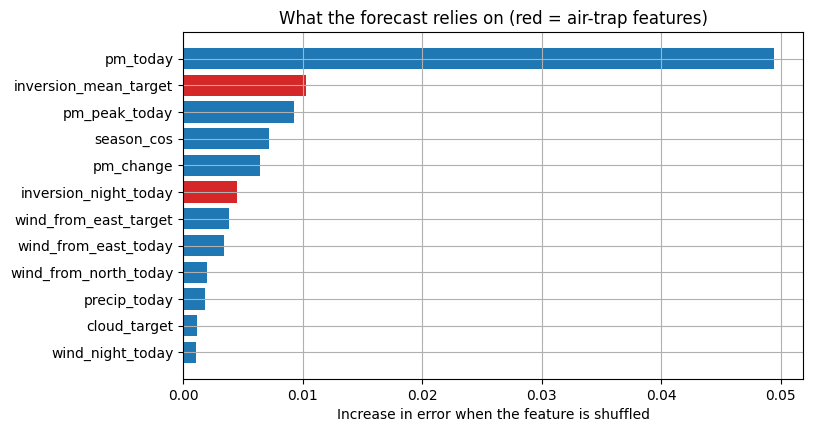

,0
pm_today,0.0494
inversion_mean_target,0.0103
pm_peak_today,0.0093
season_cos,0.0072
pm_change,0.0064
inversion_night_today,0.0045
wind_from_east_target,0.0038
wind_from_east_today,0.0034


In [8]:
last_season, tr_last, te_last = list(folds(t))[-1]
model = fit(tr_last[FEATURES], tr_last["y"])
change = np.log1p(te_last["y"]) - np.log1p(te_last["pm_today"])
imp = permutation_importance(model, te_last[FEATURES], change, n_repeats=10,
                             random_state=0, scoring="neg_mean_absolute_error")
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False)
top = importance.head(12)[::-1]
colors = ["tab:red" if TRAP_FEATURES and c.startswith(tuple(TRAP_FEATURES)) else "tab:blue" for c in top.index]
plt.figure(figsize=(8, 4.5))
plt.barh(top.index, top.values, color=colors)
plt.xlabel("Increase in error when the feature is shuffled")
plt.title("What the forecast relies on (red = air-trap features)")
plt.savefig("fig_importance.png", dpi=150, bbox_inches="tight")
plt.show()
importance.head(8).round(4)

## 7. The bad days the alert missed

Looking at the failures shows where the model should not be trusted.

In [9]:
bad_mask, alert_mask = res["y"] >= BAD, res["alert"]
show = ["pm_today", "wind_target"] + (["inversion_night_target"] if HAS_INVERSION else [])

missed = test[bad_mask & ~alert_mask]
missed_table = pd.DataFrame({
    "target day": (missed.index + pd.Timedelta(days=1)).date,
    "actual": missed["y"].round(0).values,
    "forecast": res.loc[missed.index, "pred"].round(0).values,
    **{c: missed[c].round(1).values for c in show},
})
print(f"Missed {len(missed)} of {int(bad_mask.sum())} bad days")

groups = {"missed bad days": bad_mask & ~alert_mask, "caught bad days": bad_mask & alert_mask}
missed_vs_caught = pd.DataFrame({k: test.loc[m, ["y"] + show].mean() for k, m in groups.items()}).round(1)
missed_vs_caught.index = ["actual PM2.5"] + show
print(missed_vs_caught.to_string())
missed_table.head(15)

Missed 22 of 165 bad days
                        missed bad days  caught bad days
actual PM2.5                       78.6            133.8
pm_today                           38.9            121.7
wind_target                         7.3              6.0
inversion_night_target             -5.2             -2.3


,target day,actual,forecast,pm_today,wind_target,inversion_night_target
0,2020-11-17,64.0,21.0,11.6,8.6,-6.7
1,2020-11-30,101.0,40.0,17.4,4.8,-2.6
2,2021-01-19,62.0,30.0,29.2,10.1,-5.5
3,2021-01-20,66.0,25.0,62.3,11.7,-5.6
4,2021-01-21,153.0,31.0,65.7,9.1,-11.2
5,2021-01-31,92.0,39.0,81.1,9.4,-8.6
6,2021-02-01,74.0,42.0,91.8,7.8,-9.0
7,2021-02-26,57.0,25.0,16.1,6.9,-6.2
8,2021-11-13,71.0,29.0,20.7,7.2,-5.9
9,2021-12-04,70.0,26.0,13.8,6.7,-2.6


## 8. An honest range

Two more models predict the 10th and 90th percentile. The range is then widened by the amount that would have been needed to cover 80% of days in earlier seasons, and checked on the test seasons.

The 80% range contained the real value on 87% of test days (average width 45 ug/m3)


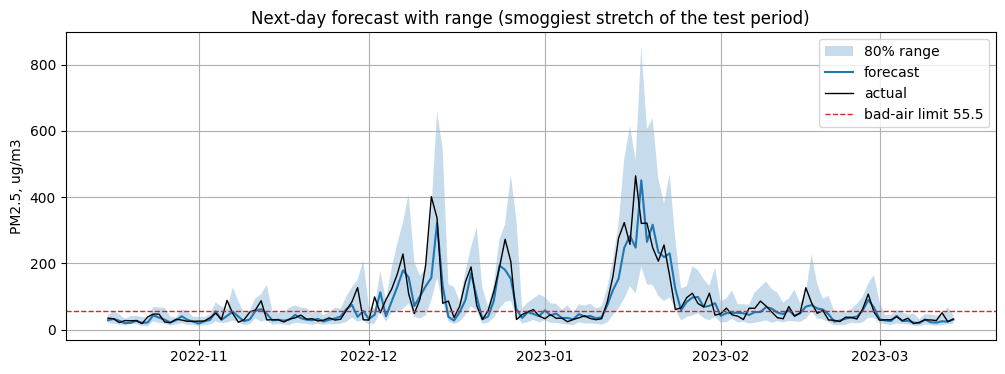

In [10]:
def walk_forward_ranges(table, cols):
    parts = []
    for ts, tr, te in folds(table):
        lo_m, hi_m = fit(tr[cols], tr["y"], 0.1), fit(tr[cols], tr["y"], 0.9)
        o_lo, o_hi = unseen_train_predictions(tr, cols, 0.1), unseen_train_predictions(tr, cols, 0.9)
        actual = np.log1p(tr.loc[o_lo.index, "y"])
        shortfall = np.maximum(np.log1p(o_lo) - actual, actual - np.log1p(o_hi))
        widen = float(np.quantile(shortfall, 0.8))
        parts.append(pd.DataFrame({
            "low": np.expm1(np.log1p(predict(lo_m, te[cols])) - widen),
            "high": np.expm1(np.log1p(predict(hi_m, te[cols])) + widen)}))
    return pd.concat(parts)


ranges = walk_forward_ranges(t, FEATURES)
low = np.minimum(ranges["low"], res["pred"]).clip(lower=0)
high = np.maximum(ranges["high"], res["pred"])
coverage = float(((res["y"] >= low) & (res["y"] <= high)).mean())
print(f"The 80% range contained the real value on {coverage:.0%} of test days "
      f"(average width {float((high - low).mean()):.0f} ug/m3)")

# Plot the smoggiest 150-day stretch of the test period
start = max(int(np.argmax(res["y"].rolling(150, min_periods=1).mean().values)) - 149, 0)
view = res.index[start:start + 150]
x = view + pd.Timedelta(days=1)
plt.figure(figsize=(12, 4))
plt.fill_between(x, low[view], high[view], alpha=0.25, label="80% range")
plt.plot(x, res.loc[view, "pred"], label="forecast")
plt.plot(x, res.loc[view, "y"], color="k", lw=1, label="actual")
plt.axhline(BAD, color="tab:red", ls="--", lw=1, label=f"bad-air limit {BAD:g}")
plt.ylabel("PM2.5, ug/m3")
plt.title("Next-day forecast with range (smoggiest stretch of the test period)")
plt.legend()
plt.savefig("fig_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Up to a week ahead

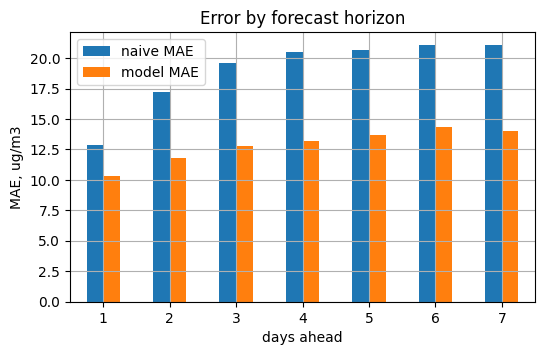

,naive MAE,model MAE,bad days caught (alert at limit)
days ahead,,,
1,12.90,10.31,0.74
2,17.24,11.77,0.69
3,19.62,12.78,0.71
4,20.48,13.17,0.64
5,20.66,13.71,0.59
6,21.07,14.32,0.68
7,21.05,13.99,0.68


In [11]:
rows = []
for h in range(1, 8):
    r = walk_forward(make_table(h), FEATURES, h, tune_alert=False)
    rows.append({"days ahead": h,
                 "naive MAE": round(mae(r["y"], r["naive"]), 2),
                 "model MAE": round(mae(r["y"], r["pred"]), 2),
                 "bad days caught (alert at limit)": alert_stats(r["y"], r["pred"] >= BAD)["recall"]})
horizons = pd.DataFrame(rows).set_index("days ahead")
horizons[["naive MAE", "model MAE"]].plot(kind="bar", figsize=(6, 3.5), rot=0,
                                          title="Error by forecast horizon", ylabel="MAE, ug/m3")
plt.savefig("fig_horizons.png", dpi=150, bbox_inches="tight")
plt.show()
horizons

## 10. The alert people would read

The same warning in Kyrgyz, Russian and English. The "cigarettes" line uses Berkeley Earth's rule of thumb (about 22 ug/m3 of PM2.5 over a day is roughly one cigarette). It is a rough comparison to make the number easier to picture, not a medical statement.

In [12]:
def cigarettes(pm):
    return pm / 22.0


def alert_message(pm, lo, hi, is_alert):
    pm, lo, hi = round(float(pm)), round(float(lo)), round(float(hi))
    if is_alert:
        return {
            "KY": (f"ЭСКЕРТҮҮ, Бишкек: эртең PM2.5 болжол менен {pm} мкг/м³ болот (күтүлгөн аралык {lo}–{hi}). "
                   "Аба ден соолукка зыяндуу. Сыртта азыраак жүрүңүз, спорт сабактарын имарат ичинде өткөрүңүз, "
                   "терезелерди жабык кармаңыз."),
            "RU": (f"ПРЕДУПРЕЖДЕНИЕ, Бишкек: завтра PM2.5 ожидается около {pm} мкг/м³ (вероятный диапазон {lo}–{hi}). "
                   "Воздух вреден для здоровья. Сократите время на улице, проводите занятия спортом в помещении, "
                   "держите окна закрытыми."),
            "EN": (f"ALERT, Bishkek: tomorrow's PM2.5 is forecast at about {pm} ug/m3 (likely range {lo}-{hi}). "
                   "The air may be unhealthy. Spend less time outdoors, move sport indoors and keep windows closed."),
        }
    return {
        "KY": f"Бишкек: эртең кооптуу деңгээл күтүлбөйт. PM2.5 болжол менен {pm} мкг/м³ (күтүлгөн аралык {lo}–{hi}).",
        "RU": f"Бишкек: завтра опасный уровень не ожидается. PM2.5 около {pm} мкг/м³ (вероятный диапазон {lo}–{hi}).",
        "EN": f"Bishkek: no unhealthy level expected tomorrow. PM2.5 about {pm} ug/m3 (likely range {lo}-{hi}).",
    }


examples = {"Smoggiest forecast in the test period": res["pred"].idxmax(), "Last day of the test period": res.index[-1]}
for title, d in examples.items():
    print(f"--- {title}: forecast made on {d.date()} for {(d + pd.Timedelta(days=1)).date()} ---")
    for lang, text in alert_message(res.loc[d, "pred"], low[d], high[d], res.loc[d, "alert"]).items():
        print(f"[{lang}] {text}")
    print(f"(Actual value: {res.loc[d, 'y']:.0f} ug/m3, roughly {cigarettes(res.loc[d, 'y']):.1f} cigarettes that day)\n")

--- Smoggiest forecast in the test period: forecast made on 2023-01-17 for 2023-01-18 ---
[KY] ЭСКЕРТҮҮ, Бишкек: эртең PM2.5 болжол менен 451 мкг/м³ болот (күтүлгөн аралык 190–855). Аба ден соолукка зыяндуу. Сыртта азыраак жүрүңүз, спорт сабактарын имарат ичинде өткөрүңүз, терезелерди жабык кармаңыз.
[RU] ПРЕДУПРЕЖДЕНИЕ, Бишкек: завтра PM2.5 ожидается около 451 мкг/м³ (вероятный диапазон 190–855). Воздух вреден для здоровья. Сократите время на улице, проводите занятия спортом в помещении, держите окна закрытыми.
[EN] ALERT, Bishkek: tomorrow's PM2.5 is forecast at about 451 ug/m3 (likely range 190-855). The air may be unhealthy. Spend less time outdoors, move sport indoors and keep windows closed.
(Actual value: 320 ug/m3, roughly 14.6 cigarettes that day)

--- Last day of the test period: forecast made on 2024-06-29 for 2024-06-30 ---
[KY] Бишкек: эртең кооптуу деңгээл күтүлбөйт. PM2.5 болжол менен 10 мкг/м³ (күтүлгөн аралык 4–18).
[RU] Бишкек: завтра опасный уровень не ожидается. PM2

## 11. Results summary

Copy the block below into the README.

In [13]:
a_naive, a_model = alerts.iloc[0], alerts.iloc[2]
th_lo, th_hi = res["threshold"].min(), res["threshold"].max()

# The same accuracy in percent: error against the average level, and the typical miss as a share of the real value
level, level_w = float(res["y"].mean()), float(res["y"][winter].mean())
typical_miss = lambda p: float(((res["y"] - p).abs() / res["y"]).median())
close = lambda p: float((((res["y"] - p).abs() / res["y"]) <= 0.25).mean())
lines = [
    f"- **Data:** {PM_SOURCE}; weather from Open-Meteo. {len(t)} days, {t.index.min().date()} to {t.index.max().date()}.",
    f"- **Tested on:** {res.index.min().date()} to {res.index.max().date()}, {len(res)} days in "
    f"{res['season'].nunique()} seasons, each forecast by a model trained only on earlier seasons. "
    f"{int(a_model['bad days'])} bad days at {BAD:g} ug/m3 ({BAD_LABEL}).",
    f"- **Accuracy (MAE, ug/m3):** naive {accuracy.iloc[0, 0]} vs model {accuracy.iloc[2, 0]} on all days; "
    f"naive {accuracy.iloc[0, 1]} vs model {accuracy.iloc[2, 1]} on winter days.",
    f"- **Without the target day's weather:** model {accuracy.iloc[1, 0]} on all days and {accuracy.iloc[1, 1]} on "
    f"winter days. A real forecast would land between this and the line above.",
    f"- **In percent:** PM2.5 averaged {level:.1f} ug/m3 on test days ({level_w:.1f} in winter). The model's average "
    f"error is {accuracy.iloc[2, 0] / level:.0%} of that level (naive {accuracy.iloc[0, 0] / level:.0%}). "
    f"Half of the model's forecasts were within {typical_miss(res['pred']):.0%} of the real value "
    f"(naive {typical_miss(res['naive']):.0%}), and {close(res['pred']):.0%} were within 25% of it "
    f"(naive {close(res['naive']):.0%}).",
    f"- **Alert (thresholds {th_lo:g} to {th_hi:g}):** caught {int(a_model['caught'])} of {int(a_model['bad days'])} "
    f"bad days with {int(a_model['false alarms'])} false alarms (critical success index {a_model['CSI']}). "
    f"The naive rule caught {int(a_naive['caught'])} with {int(a_naive['false alarms'])} false alarms "
    f"(critical success index {a_naive['CSI']}).",
    f"- **Air-trap experiment:** {verdict}",
    f"- **Top drivers:** {', '.join(importance.head(5).index)}.",
    f"- **Range:** the 80% range held the real value on {coverage:.0%} of test days.",
    "- **Horizon (naive / model MAE):** " + ", ".join(
        f"{h} day: {horizons.loc[h, 'naive MAE']} / {horizons.loc[h, 'model MAE']}" for h in horizons.index) + ".",
]
print("\n".join(lines))

- **Data:** US Embassy Bishkek monitor (measured), archived on Zenodo (record 12720883); weather from Open-Meteo. 1783 days, 2019-02-06 to 2024-06-29.
- **Tested on:** 2020-07-02 to 2024-06-29, 1306 days in 4 seasons, each forecast by a model trained only on earlier seasons. 165 bad days at 55.5 ug/m3 (Unhealthy (US AQI)).
- **Accuracy (MAE, ug/m3):** naive 12.9 vs model 10.31 on all days; naive 29.0 vs model 22.59 on winter days.
- **Without the target day's weather:** model 11.04 on all days and 24.63 on winter days. A real forecast would land between this and the line above.
- **In percent:** PM2.5 averaged 31.5 ug/m3 on test days (62.8 in winter). The model's average error is 33% of that level (naive 41%). Half of the model's forecasts were within 23% of the real value (naive 25%), and 54% were within 25% of it (naive 50%).
- **Alert (thresholds 41.6 to 44.4):** caught 143 of 165 bad days with 88 false alarms (critical success index 0.57). The naive rule caught 113 with 52 false al

## 12. A real forecast for tomorrow

Everything above was tested on past days. This section makes an actual forecast for tomorrow. The US Embassy feed ended in March 2025, so today's smog level cannot be downloaded: type today's average PM2.5 for Bishkek (from any air-quality app) into `TODAY_PM25` and run the two cells. The notebook downloads the real weather forecast for today and tomorrow and uses the same model, trained on all the data.

It also prints an outlook for the next seven days, with the error each number of days ahead showed in testing. The further ahead, the less the weather forecast itself can be trusted, so days 4 to 7 are a rough guide. A month ahead cannot be forecast day by day, because the weather cannot.

With a single typed-in reading the model lacks the past week's history, so these forecasts are less accurate than the tested results above.

In [14]:
TODAY_PM25 = 60          #@param {type:"number"}


def live_weather():
    # Open-Meteo forecast for yesterday, today and the next two days, same variables as the history
    def get(lat, lon, variables):
        j = get_json("https://api.open-meteo.com/v1/forecast", dict(
            latitude=lat, longitude=lon, hourly=",".join(variables),
            past_days=1, forecast_days=9, timezone=TZ))
        h = pd.DataFrame(j["hourly"])
        h["time"] = pd.to_datetime(h["time"])
        return h.set_index("time")
    w = get(LAT, LON, [c for c in wx_hourly.columns if c != "temperature_mountain"])
    if "temperature_mountain" in wx_hourly.columns:
        w["temperature_mountain"] = get(LAT_M, LON_M, ["temperature_2m"])["temperature_2m"]
    return w


live_hourly = live_weather()
print("Weather forecast downloaded:", live_hourly.index.min(), "to", live_hourly.index.max())

Weather forecast downloaded: 2026-11-15 00:00:00 to 2026-11-24 23:00:00


In [15]:
# Train on all the data, then forecast tomorrow from today's reading and the weather forecast
final_model = fit(t[FEATURES], t["y"])
final_low, final_high = fit(t[FEATURES], t["y"], 0.1), fit(t[FEATURES], t["y"], 0.9)
o_lo, o_hi = unseen_train_predictions(t, FEATURES, 0.1), unseen_train_predictions(t, FEATURES, 0.9)
actual_log = np.log1p(t.loc[o_lo.index, "y"])
widen_live = float(np.quantile(np.maximum(np.log1p(o_lo) - actual_log, actual_log - np.log1p(o_hi)), 0.8))

live_day = daily_weather(live_hourly)
today = pd.Timestamp.now(tz=TZ).normalize().tz_localize(None)
tomorrow = today + pd.Timedelta(days=1)

row = {c: np.nan for c in FEATURES}
row["pm_today"] = float(TODAY_PM25)
for c in day.columns:
    if c in live_day.columns:
        row[c + "_today"] = live_day.loc[today, c]
        row[c + "_target"] = live_day.loc[tomorrow, c]
row["season_sin"] = np.sin(2 * np.pi * tomorrow.dayofyear / 365.25)
row["season_cos"] = np.cos(2 * np.pi * tomorrow.dayofyear / 365.25)
row["weekday"] = tomorrow.dayofweek
X_live = pd.DataFrame([row])[FEATURES]

live_pred = float(predict(final_model, X_live).iloc[0])
live_low = min(float(np.expm1(np.log1p(predict(final_low, X_live).iloc[0]) - widen_live)), live_pred)
live_high = max(float(np.expm1(np.log1p(predict(final_high, X_live).iloc[0]) + widen_live)), live_pred)
live_threshold = float(res["threshold"].iloc[-1])            # the alert threshold of the latest season
live_alert = live_pred >= live_threshold

print(f"Today ({today.date()}): PM2.5 {TODAY_PM25} ug/m3 (typed in)")
print(f"Forecast for {tomorrow.date()}: {live_pred:.0f} ug/m3, likely {live_low:.0f} to {live_high:.0f}. "
      f"Alert: {'YES' if live_alert else 'no'} (fires at {live_threshold:g})\n")
for lang, text in alert_message(live_pred, live_low, live_high, live_alert).items():
    print(f"[{lang}] {text}")

# The week ahead: one model per number of days ahead, each trained on all the data
outlook, live_models = [], {}
for h in range(1, 8):
    th = make_table(h)
    model_h = fit(th[FEATURES], th["y"])
    live_models[h] = model_h
    target = today + pd.Timedelta(days=h)
    r = dict(row)
    for c in day.columns:
        r[c + "_target"] = live_day.loc[target, c] if (c in live_day.columns and target in live_day.index) else np.nan
    r["season_sin"] = np.sin(2 * np.pi * target.dayofyear / 365.25)
    r["season_cos"] = np.cos(2 * np.pi * target.dayofyear / 365.25)
    r["weekday"] = target.dayofweek
    p = float(predict(model_h, pd.DataFrame([r])[FEATURES]).iloc[0])
    outlook.append({"day": target.date(), "days ahead": h, "forecast": round(p),
                    "typical error when tested": horizons.loc[h, "model MAE"],
                    "alert": "YES" if p >= live_threshold else "no"})
outlook = pd.DataFrame(outlook).set_index("day")
print("\nOutlook for the week ahead:")
print(outlook.to_string())

Today (2026-11-16): PM2.5 60 ug/m3 (typed in)
Forecast for 2026-11-17: 84 ug/m3, likely 41 to 118. Alert: YES (fires at 41.6)

[KY] ЭСКЕРТҮҮ, Бишкек: эртең PM2.5 болжол менен 84 мкг/м³ болот (күтүлгөн аралык 41–118). Аба ден соолукка зыяндуу. Сыртта азыраак жүрүңүз, спорт сабактарын имарат ичинде өткөрүңүз, терезелерди жабык кармаңыз.
[RU] ПРЕДУПРЕЖДЕНИЕ, Бишкек: завтра PM2.5 ожидается около 84 мкг/м³ (вероятный диапазон 41–118). Воздух вреден для здоровья. Сократите время на улице, проводите занятия спортом в помещении, держите окна закрытыми.
[EN] ALERT, Bishkek: tomorrow's PM2.5 is forecast at about 84 ug/m3 (likely range 41-118). The air may be unhealthy. Spend less time outdoors, move sport indoors and keep windows closed.

Outlook for the week ahead:
            days ahead  forecast  typical error when tested alert
day                                                              
2026-11-17           1        84                      10.31   YES
2026-11-18           2        70   

## 13. Data for the demo page

The demo page in this repository replays these forecasts. It reads the line below straight from this notebook, so what it shows is exactly what was computed here. Each entry is: the evening the forecast was made, the next day's actual PM2.5, the forecast, the low and high end of its range, and whether the alert fired.

In [16]:
import json

demo_rows = [[d.strftime("%Y-%m-%d"), int(round(res.loc[d, "y"])), int(round(res.loc[d, "pred"])),
              int(round(low[d])), int(round(high[d])), int(res.loc[d, "alert"])] for d in res.index]
print("DEMO_DATA=" + json.dumps({"bad": BAD, "rows": demo_rows}, separators=(",", ":")))

DEMO_DATA={"bad":55.5,"rows":[["2020-07-02",6,8,4,13,0],["2020-07-05",5,3,1,5,0],["2020-07-06",3,6,3,11,0],["2020-07-07",9,4,1,8,0],["2020-07-08",7,10,4,22,0],["2020-07-09",5,7,3,14,0],["2020-07-13",7,8,3,13,0],["2020-07-14",6,8,4,20,0],["2020-07-15",6,7,3,16,0],["2020-07-16",2,7,3,13,0],["2020-07-17",3,3,1,7,0],["2020-07-18",4,4,1,9,0],["2020-07-19",4,4,2,11,0],["2020-07-22",4,4,1,6,0],["2020-07-23",6,5,2,11,0],["2020-07-24",3,8,3,17,0],["2020-07-25",6,4,2,7,0],["2020-07-31",3,5,3,7,0],["2020-08-01",3,3,1,7,0],["2020-08-02",3,3,1,7,0],["2020-08-05",4,4,2,6,0],["2020-08-06",5,7,3,14,0],["2020-08-07",4,6,3,13,0],["2020-08-08",4,4,1,10,0],["2020-08-09",2,5,2,12,0],["2020-08-10",3,3,1,7,0],["2020-08-11",8,4,2,8,0],["2020-08-12",8,9,4,18,0],["2020-08-13",4,10,4,19,0],["2020-08-14",23,6,3,13,0],["2020-08-15",5,14,6,50,0],["2020-08-16",13,5,2,9,0],["2020-08-17",4,9,5,27,0],["2020-08-18",4,5,2,8,0],["2020-08-19",5,5,2,10,0],["2020-08-20",3,5,3,12,0],["2020-08-21",6,4,1,8,0],["2020-08-22",7,6,

The demo page also makes a live week-ahead forecast in the browser. For that it needs the trained models themselves, so the cell below writes the seven models (one per number of days ahead) as compressed text. The check at the end runs the exported copy on the same input as section 12 and compares the two answers.

In [17]:
import base64
import gzip


def export_tree(nodes, i=0):
    # A tree as nested lists: [feature, threshold, missing goes left, left branch, right branch]; a leaf is a number
    n = nodes[i]
    if n["is_leaf"]:
        return round(float(n["value"]), 6)
    threshold = float(n["num_threshold"])
    threshold = float(f"{threshold:.7g}") if np.isfinite(threshold) else 1e300
    return [int(n["feature_idx"]), threshold, int(n["missing_go_to_left"]),
            export_tree(nodes, int(n["left"])), export_tree(nodes, int(n["right"]))]


def export_model(m):
    return {"base": float(np.ravel(m._baseline_prediction)[0]),
            "trees": [export_tree(p[0].nodes) for p in m._predictors]}


def run_exported(model, x):
    total = model["base"]
    for node in model["trees"]:
        while isinstance(node, list):
            v = x[node[0]]
            node = (node[3] if node[2] else node[4]) if np.isnan(v) else (node[3] if v <= node[1] else node[4])
        total += node
    return total


live_export = {
    "features": FEATURES,
    "wx_vars": [c for c in wx_hourly.columns if c != "temperature_mountain"],
    "has_mountain": "temperature_mountain" in wx_hourly.columns,
    "lat": LAT, "lon": LON, "lat_m": LAT_M, "lon_m": LON_M,
    "elev_city": float(ELEV_CITY), "elev_mountain": float(ELEV_MOUNTAIN),
    "bad": BAD, "threshold": live_threshold,
    "mae": {str(h): float(horizons.loc[h, "model MAE"]) for h in range(1, 8)},
    "models": {str(h): export_model(live_models[h]) for h in range(1, 8)},
}
x_check = X_live.iloc[0].astype(float).values
check = float(np.expm1(np.log1p(x_check[FEATURES.index("pm_today")]) + run_exported(live_export["models"]["1"], x_check)))
print(f"Export check: notebook forecast {live_pred:.2f}, exported model {check:.2f}")
packed = base64.b64encode(gzip.compress(json.dumps(live_export, separators=(",", ":")).encode())).decode()
print(f"Exported models: {len(packed) // 1000} thousand characters")
print("LIVE_MODEL=" + packed)

Export check: notebook forecast 84.30, exported model 84.30
Exported models: 81 thousand characters
LIVE_MODEL=...


## Limits

- One monitor stands in for the whole city, and it sits in a cleaner southern district. Smog in Bishkek differs a lot between neighbourhoods.
- The target day's weather is a reanalysis standing in for a forecast, so real-world accuracy would be somewhat lower.
- The inversion measure is a simple proxy: a mountain grid cell's temperature minus the city's, from a weather model with cells about 10 km wide.
- Winters differ a lot from each other, and there are only a few of them. Results could shift with another year.
- The measured data ends in mid-2024.
- Prototype only. Not health advice.